In [2]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import healpy as hp

Populating the interactive namespace from numpy and matplotlib


In [54]:
pwd

'/work/xiangchong.li/superonionGW/code/G3sim-HSC/notebook/rgcSim'

In [37]:
utilities.field_names

{'XMM': 'W02',
 'GAMA09H': 'W03',
 'WIDE12H': 'W04_WIDE12H',
 'GAMA15H': 'W04_GAMA15H',
 'VVDS': 'W05',
 'HECTOMAP': 'W06'}

In [52]:
def fig8rho(prefix):
    # load data
    #fields=np.array(['HECTOMAP','GAMA09H','WIDE12H','GAMA15H','VVDS','XMM'])
    fields=np.array(['W06','W03','WIDE12H','GAMA15H','W05','W02'])
    
    rp,r1w02t,er1w02t,r2w02t,er2w02t,r3w02t,er3w02t,r4w02t,er4w02t,\
    r5w02t,er5w02t=np.loadtxt(prefix+fields[5]+'_rhos_true.dat',unpack=True)
    rp,r1w02f,er1w02f,r2w02f,er2w02f,r3w02f,er3w02f,r4w02f,er4w02f,\
    r5w02f,er5w02f=np.loadtxt(prefix+fields[5]+'_rhos_false.dat',unpack=True)

    rp,r1w03t,er1w03t,r2w03t,er2w03t,r3w03t,er3w03t,r4w03t,er4w03t,\
    r5w03t,er5w03t=np.loadtxt(prefix+fields[1]+'_rhos_true.dat',unpack=True)
    rp,r1w03f,er1w03f,r2w03f,er2w03f,r3w03f,er3w03f,r4w03f,er4w03f,\
    r5w03f,er5w03f=np.loadtxt(prefix+fields[1]+'_rhos_false.dat',unpack=True)

    rp,r1w04t,er1w04t,r2w04t,er2w04t,r3w04t,er3w04t,r4w04t,er4w04t,\
    r5w04t,er5w04t=np.loadtxt(prefix+'WIDE12H_rhos_true.dat',unpack=True)
    rp,r1w04f,er1w04f,r2w04f,er2w04f,r3w04f,er3w04f,r4w04f,er4w04f,\
    r5w04f,er5w04f=np.loadtxt(prefix+'WIDE12H_rhos_false.dat',unpack=True)

    rp,r1w04gt,er1w04gt,r2w04gt,er2w04gt,r3w04gt,er3w04gt,r4w04gt,er4w04gt,\
    r5w04gt,er5w04gt=np.loadtxt(prefix+'GAMA15H_rhos_true.dat',unpack=True)
    rp,r1w04gf,er1w04gf,r2w04gf,er2w04gf,r3w04gf,er3w04gf,r4w04gf,er4w04gf,\
    r5w04gf,er5w04gf=np.loadtxt(prefix+'GAMA15H_rhos_false.dat',unpack=True)

    rp,r1w05t,er1w05t,r2w05t,er2w05t,r3w05t,er3w05t,r4w05t,er4w05t,\
    r5w05t,er5w05t=np.loadtxt(prefix+fields[4]+'_rhos_true.dat',unpack=True)
    rp,r1w05f,er1w05f,r2w05f,er2w05f,r3w05f,er3w05f,r4w05f,er4w05f,\
    r5w05f,er5w05f=np.loadtxt(prefix+fields[4]+'_rhos_false.dat',unpack=True)

    rp,r1w06t,er1w06t,r2w06t,er2w06t,r3w06t,er3w06t,r4w06t,er4w06t,\
    r5w06t,er5w06t=np.loadtxt(prefix+fields[0]+'_rhos_true.dat',unpack=True)
    rp,r1w06f,er1w06f,r2w06f,er2w06f,r3w06f,er3w06f,r4w06f,er4w06f,\
    r5w06f,er5w06f=np.loadtxt(prefix+fields[0]+'_rhos_false.dat',unpack=True)

    rr,rho135,rho24=np.loadtxt(os.path.join(prefix,'rho_requirements.txt'),unpack=True,comments='#')
    xx=np.array([0.05,1])
    yy=np.zeros(len(rr))
    yr=yy*0.0+1e-6

    fig=plt.figure(figsize=(15,9))
    ax=fig.add_subplot(3,2,1)
    ax.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.8,facecolor='grey',linewidth=0.0,zorder=2)
    ax.plot(rr,yy+(rho135)*1e+6,'k-',linewidth=2.5)
    ax.plot(rr,yy-(rho135)*1e+6,'k-',linewidth=2.5)
    ax.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,alpha=0.4,facecolor='grey',linewidth=0.0,zorder=1)
    ax.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.5,facecolor='grey',linewidth=0.0)
    ax.plot(rr,yy,'k--',linewidth=2.5)
    ax.errorbar(rp,r1w02t,yerr=er1w02t,fmt='s-c',ms=8,elinewidth=2.0,label='W02')
    ax.errorbar(rp,r1w02f,yerr=er1w02f,fmt='s--c',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r1w03t,yerr=er1w03t,fmt='d-',color='orange',ms=8,elinewidth=2.0,label='W03')
    ax.errorbar(rp,r1w03f,yerr=er1w03f,fmt='d--',color='orange',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r1w04t,yerr=er1w04t,fmt='x-y',ms=8,elinewidth=2.0,label='WIDE12H')
    ax.errorbar(rp,r1w04f,yerr=er1w04f,fmt='x--y',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r1w04gt,yerr=er1w04gt,fmt='o-k',ms=8,elinewidth=2.0,label='GAMA15H')
    ax.errorbar(rp,r1w04gf,yerr=er1w04gf,fmt='o--k',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r1w05t,yerr=er1w05t,fmt='+-b',ms=8,elinewidth=2.0,label='W05')
    ax.errorbar(rp,r1w05f,yerr=er1w05f,fmt='+--b',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r1w06t,yerr=er1w06t,fmt='^-r',ms=8,elinewidth=2.0,label='W06')
    ax.errorbar(rp,r1w06f,yerr=er1w06f,fmt='^--r',ms=8,elinewidth=2.0)
    ax.set_ylim(-10.0,10.0)
    ax.set_yticks(())
    ax.set_xlim(0.05,1.0)
    ax.set_xscale('log')
    ax.set_yscale('symlog',linthresy=3.0)
    ax.set_yticks(np.array([-10,-1,0,1,10]),\
        ('$-10^{-5}$','$-10^{-6}$', \
        '$0.0$','$10^{-6}$','$10^{-5}$'))
    ax.set_ylabel(r"$\rho_1$",fontsize=20.0)

    ax=fig.add_subplot(3,2,2)
    ax.fill_between(rr,yy+(rho24)*1e+6/1.414,yy-(rho24)*1e+6/1.414,alpha=0.8,facecolor='grey',linewidth=0.0,zorder=2)
    ax.plot(rr,yy+(rho24)*1e+6,'k-',linewidth=2.5)
    ax.plot(rr,yy-(rho24)*1e+6,'k-',linewidth=2.5)
    ax.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,alpha=0.4,facecolor='grey',linewidth=0.0,zorder=1)
    ax.fill_between(rr,yy+(rho24)*1e+6/1.414,yy-(rho24)*1e+6/1.414,alpha=0.5,facecolor='grey',linewidth=0.0)
    ax.plot(rr,yy,'k--',linewidth=2.5)
    ax.errorbar(rp,r2w02t,yerr=er2w02t,fmt='s-c',ms=8,elinewidth=2.0,label='W02')
    ax.errorbar(rp,r2w02f,yerr=er2w02f,fmt='s--c',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r2w03t,yerr=er2w03t,fmt='d-',color='orange',ms=8,elinewidth=2.0,label='W03')
    ax.errorbar(rp,r2w03f,yerr=er2w03f,fmt='d--',color='orange',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r2w04t,yerr=er2w04t,fmt='x-y',ms=8,elinewidth=2.0,label='WIDE12H')
    ax.errorbar(rp,r2w04f,yerr=er2w04f,fmt='x--y',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r2w04gt,yerr=er2w04gt,fmt='o-k',ms=8,elinewidth=2.0,label='GAMA15H')
    ax.errorbar(rp,r2w04gf,yerr=er2w04gf,fmt='o--k',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r2w05t,yerr=er2w05t,fmt='+-b',ms=8,elinewidth=2.0,label='W05')
    ax.errorbar(rp,r2w05f,yerr=er2w05f,fmt='+--b',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r2w06t,yerr=er2w06t,fmt='^-r',ms=8,elinewidth=2.0,label='W06')
    ax.errorbar(rp,r2w06f,yerr=er2w06f,fmt='^--r',ms=8,elinewidth=2.0)
    ax.set_ylim(-1000.0,1000.0)
    ax.set_yticks(())
    ax.set_xlim(0.05,1.0)
    ax.set_xscale('log')
    ax.set_yscale('symlog',linthresy=10.0)
    ax.set_yticks(np.array([-1000,-100,-10,-1.0,0,1,10,100,1000]),\
         ('-$10^{-3}$','-$10^{-4}$','$-10^{-5}$','$-10^{-6}$',\
          '$0.0$','$10^{-6}$','$10^{-5}$','$10^{-4}$','$10^{-3}$'))
    ax.set_ylabel(r"$\rho_2$",fontsize=20.0)
    #plt.xlabel(r"$\theta (degree)$",fontsize=15.0)

    plt.subplot(3,2,3)
    plt.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.8,facecolor='grey',linewidth=0.0,zorder=2)
    plt.plot(rr,yy+(rho135)*1e+6,'k-',linewidth=2.5)
    plt.plot(rr,yy-(rho135)*1e+6,'k-',linewidth=2.5)
    plt.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,alpha=0.4,facecolor='grey',linewidth=0.0,zorder=1)
    plt.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.5,facecolor='grey',linewidth=0.0)
    plt.plot(rr,yy,'k--',linewidth=2.5)
    plt.errorbar(rp,r3w02t,yerr=er3w02t,fmt='s-c',ms=8,elinewidth=2.0,label='W02')
    plt.errorbar(rp,r3w02f,yerr=er3w02f,fmt='s--c',ms=8,elinewidth=2.0)
    plt.errorbar(rp,r3w03t,yerr=er3w03t,fmt='d-',color='orange',ms=8,elinewidth=2.0,label='W03')
    plt.errorbar(rp,r3w03f,yerr=er3w03f,fmt='d--',color='orange',ms=8,elinewidth=2.0)
    plt.errorbar(rp,r3w04t,yerr=er3w04t,fmt='x-y',ms=8,elinewidth=2.0,label='WIDE12H')
    plt.errorbar(rp,r3w04f,yerr=er3w04f,fmt='x--y',ms=8,elinewidth=2.0)
    plt.errorbar(rp,r3w04gt,yerr=er3w04gt,fmt='o-k',ms=8,elinewidth=2.0,label='GAMA15H')
    plt.errorbar(rp,r3w04gf,yerr=er3w04gf,fmt='o--k',ms=8,elinewidth=2.0)
    plt.errorbar(rp,r3w05t,yerr=er3w05t,fmt='+-b',ms=8,elinewidth=2.0,label='W05')
    plt.errorbar(rp,r3w05f,yerr=er3w05f,fmt='+--b',ms=8,elinewidth=2.0)
    plt.errorbar(rp,r3w06t,yerr=er3w06t,fmt='^-r',ms=8,elinewidth=2.0,label='W06')
    plt.errorbar(rp,r3w06f,yerr=er3w06f,fmt='^--r',ms=8,elinewidth=2.0)
    plt.ylim(0.0001,1.0)
    plt.yticks(())
    plt.xlim(0.05,1.0)
    plt.xscale('log')
    #plt.yscale('log')
    plt.yscale('symlog',linthresy=1.)
    plt.yticks(np.array([0.0001,0.01,1.0]),('','$10^{-8}$','$10^{-6}$'))
    plt.ylabel(r"$\rho_3$",fontsize=20.0)
    #plt.xlabel(r"$\theta (degree)$",fontsize=15.0)

    ax=fig.add_subplot(3,2,4)
    ax.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.8,facecolor='grey',linewidth=0.0,zorder=2)
    ax.plot(rr,yy+(rho135)*1e+6,'k-',linewidth=2.5)
    ax.plot(rr,yy-(rho135)*1e+6,'k-',linewidth=2.5)
    ax.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,alpha=0.4,facecolor='grey',linewidth=0.0,zorder=1)
    ax.fill_between(rr,yy+(rho135)*1e+6/1.414,yy-(rho135)*1e+6/1.414,alpha=0.5,facecolor='grey',linewidth=0.0)
    
    
    ax.errorbar(rp,r4w02t,yerr=er4w02t,fmt='s-c',ms=8,elinewidth=2.0,label='XMM')
    ax.errorbar(rp,r4w02f,yerr=er4w02f,fmt='s--c',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r4w03t,yerr=er4w03t,fmt='d-',color='orange',ms=8,elinewidth=2.0,label='GAMA09H')
    ax.errorbar(rp,r4w03f,yerr=er4w03f,fmt='d--g',color='orange',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r4w04t,yerr=er4w04t,fmt='x-y',ms=8,elinewidth=2.0,label='WIDE12H')
    ax.errorbar(rp,r4w04f,yerr=er4w04f,fmt='x--y',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r4w04gt,yerr=er4w04gt,fmt='o-k',ms=8,elinewidth=2.0,label='GAMA15H')
    ax.errorbar(rp,r4w04gf,yerr=er4w04gf,fmt='o--k',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r4w05t,yerr=er4w05t,fmt='+-b',ms=8,elinewidth=2.0,label='VVDS')
    ax.errorbar(rp,r4w05f,yerr=er4w05f,fmt='+--b',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r4w06t,yerr=er4w06t,fmt='^-r',ms=8,elinewidth=2.0,label='HECTOPMAP')
    ax.errorbar(rp,r4w06f,yerr=er4w06f,fmt='^--r',ms=8,elinewidth=2.0)
    ax.set_ylim(-10.0,10.0)
    ax.set_yticks(())
    ax.set_xlim(0.05,1.0)
    ax.set_xscale('log')
    ax.set_yscale('symlog',linthresy=10.00)
    ax.set_yticks(np.array([-10.0,-1.0,0.0,1,10]),\
         ('-$10^{-5}$',\
         '-$10^{-6}$',0.0,'$10^{-6}$','$10^{-5}$'))
    ax.set_ylabel(r"$\rho_4$",fontsize=20.0)

    
    
    ax=fig.add_subplot(3,2,5)
    ax.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,alpha=0.8,\
                    facecolor='grey',linewidth=0.0,zorder=1)
    ax.fill_between(rr,yy+(rho24)*1e+6/1.414,yy-(rho24)*1e+6/1.414,alpha=0.2,\
                    facecolor='grey',linewidth=0.0)
    ax.plot(rr,yy+(rho24)*1e+6,'k-',linewidth=2.5)
    ax.plot(rr,yy-(rho24)*1e+6,'k-',linewidth=2.5)
    
    ax.errorbar(rp,r5w02t,yerr=er5w02t*1.7,fmt='s-c',ms=8,elinewidth=2.0,label='XMM')
    ax.errorbar(rp,r5w02f,yerr=er5w02f*1.7,fmt='s--c',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r5w03t,yerr=er5w03t*1.7,fmt='d-',color='orange',ms=8,elinewidth=2.0,label='GAMA09H')
    ax.errorbar(rp,r5w03f,yerr=er5w03f*1.7,fmt='d--',color='orange',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r5w04t,yerr=er5w04t*1.7,fmt='x-y',ms=8,elinewidth=2.0,label='WIDE12H')
    ax.errorbar(rp,r5w04f,yerr=er5w04f*1.7,fmt='x--y',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r5w04gt,yerr=er5w04gt*1.7,fmt='o-k',ms=8,elinewidth=2.0,label='GAMA15H')
    ax.errorbar(rp,r5w04gf,yerr=er5w04gf*1.7,fmt='o--k',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r5w05t,yerr=er5w05t,fmt='+-b',ms=8,elinewidth=2.0,label='VVDS')
    ax.errorbar(rp,r5w05f,yerr=er5w05f,fmt='+--b',ms=8,elinewidth=2.0)
    ax.errorbar(rp,r5w06t,yerr=er5w06t,fmt='^-r',ms=8,elinewidth=2.0,label='HECTOMAP')
    ax.errorbar(rp,r5w06f,yerr=er5w06f,fmt='^--r',ms=8,elinewidth=2.0)
    
    ax.set_ylim(-1000.0,100.0)
    ax.set_yticks(())
    ax.set_yscale('symlog',linthresy=10.00)
    ax.set_yticks(np.array([-100.0,-10.0,-1.0,1.0,10.]),\
         ('-$10^{-4}$','-$10^{-5}$','-$10^{-6}$','$10^{-6}$','$10^{-5}$'))
    
    ax.set_xlim(0.05,1.0)
    ax.set_xscale('log')
    ax.set_ylabel(r"$\rho_5$",fontsize=20.0)
    ax.set_xlabel(r"$\theta [degrees]$",fontsize=15.0)
    
    plt.legend()
    #plt.savefig('psf_rho_tests.eps')
    return fig

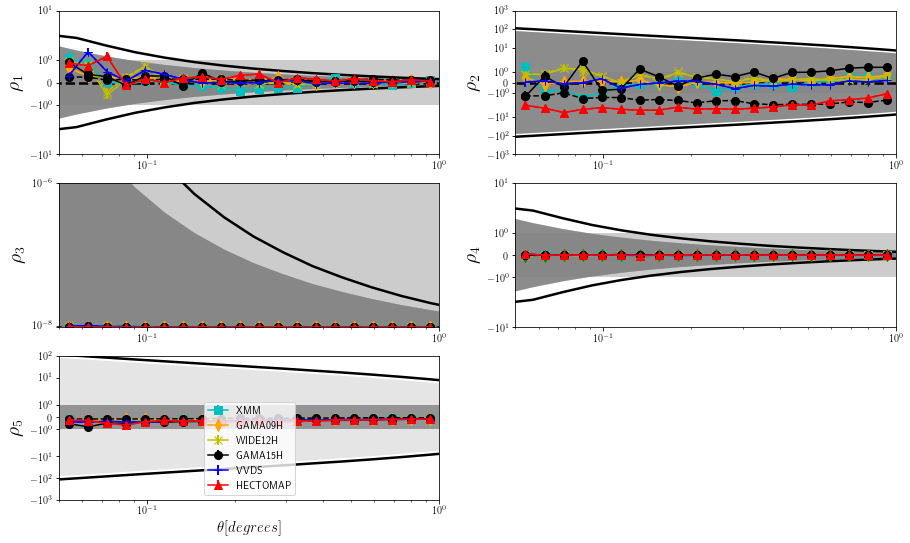

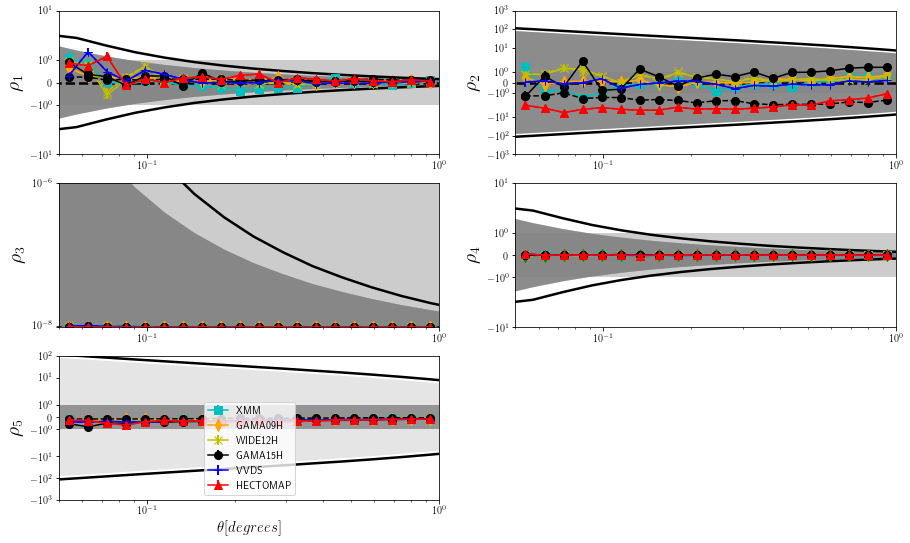

In [53]:
plt.close()
datDir='wrkDir/s19/s19-pre/psf_test_from_wentao/plot_issues/'
fig8rho(datDir)